In [3]:
import numpy as np
import pandas as pd

In [4]:
train_df = pd.read_csv('data.csv')
train_df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP002529,Male,Yes,2,Graduate,No,6700,1750.0,230.0,300.0,1.0,Semiurban,Y
1,LP001385,Male,No,0,Graduate,No,5316,0.0,136.0,360.0,1.0,Urban,Y
2,LP001926,Male,Yes,0,Graduate,No,3704,2000.0,120.0,360.0,1.0,Rural,Y
3,LP001144,Male,Yes,0,Graduate,No,5821,0.0,144.0,360.0,1.0,Urban,Y
4,LP002562,Male,Yes,1,Not Graduate,No,5333,1131.0,186.0,360.0,NaN,Urban,Y


In [5]:
train_df.shape

(430, 13)

In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 430 entries, 0 to 429
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            430 non-null    object 
 1   Gender             420 non-null    object 
 2   Married            427 non-null    object 
 3   Dependents         416 non-null    object 
 4   Education          430 non-null    object 
 5   Self_Employed      410 non-null    object 
 6   ApplicantIncome    430 non-null    int64  
 7   CoapplicantIncome  430 non-null    float64
 8   LoanAmount         414 non-null    float64
 9   Loan_Amount_Term   422 non-null    float64
 10  Credit_History     394 non-null    float64
 11  Property_Area      430 non-null    object 
 12  Loan_Status        430 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 43.8+ KB


In [7]:
train_df.isna().sum()

Loan_ID               0
Gender               10
Married               3
Dependents           14
Education             0
Self_Employed        20
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           16
Loan_Amount_Term      8
Credit_History       36
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
train_df['Gender']= train_df['Gender'].map({'Male':0, 'Female':1})
train_df['Married']= train_df['Married'].map({'No':0, 'Yes':1})
train_df['Loan_Status']= train_df['Loan_Status'].map({'N':0, 'Y':1})

train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 430 entries, 0 to 429
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            430 non-null    object 
 1   Gender             420 non-null    float64
 2   Married            427 non-null    float64
 3   Dependents         416 non-null    object 
 4   Education          430 non-null    object 
 5   Self_Employed      410 non-null    object 
 6   ApplicantIncome    430 non-null    int64  
 7   CoapplicantIncome  430 non-null    float64
 8   LoanAmount         414 non-null    float64
 9   Loan_Amount_Term   422 non-null    float64
 10  Credit_History     394 non-null    float64
 11  Property_Area      430 non-null    object 
 12  Loan_Status        430 non-null    int64  
dtypes: float64(6), int64(2), object(5)
memory usage: 43.8+ KB


In [9]:
train_df = train_df.dropna()

In [10]:
train_df.isna().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [11]:
train_df.shape

(335, 13)

In [12]:
X = train_df[['Gender', 'Married', 'ApplicantIncome', 'LoanAmount', 'Credit_History']]
y = train_df['Loan_Status']

X.shape, y.shape

((335, 5), (335,))

In [13]:
X.head()

,Gender,Married,ApplicantIncome,LoanAmount,Credit_History
0,0.0,1.0,6700,230.0,1.0
1,0.0,0.0,5316,136.0,1.0
2,0.0,1.0,3704,120.0,1.0
3,0.0,1.0,5821,144.0,1.0
5,0.0,1.0,3052,100.0,1.0


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=5)

In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(max_depth=4, random_state=5)
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=4, random_state=5)

In [16]:
model.score(X_val, y_val)

0.7313432835820896

In [17]:
model.score(X_train, y_train)

0.8134328358208955

In [18]:
import mlflow

In [19]:
mlflow.set_experiment("Loan-Default-Prediction")

<Experiment: artifact_location='file:c:/Users/SRJ/SRJ/Work/Scaler/MLOps/mlruns/1', creation_time=1792239899647, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792239899647, lifecycle_stage='active', name='Loan-Default-Prediction', tags={}, trace_location=None, workspace='default'>

In [20]:
with mlflow.start_run():
    model = RandomForestClassifier(max_depth=4, random_state=5)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag("mlflow.runName", "first_run")

    mlflow.log_param("max_depth", 4)
    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    mlflow.sklearn.log_model(model, "rf_model", serialization_format = 'pickle')

2026/10/17 20:12:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 20:12:16 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:12:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/17 20:12:16 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:12:16 INFO mlflow.utils.environment: Detected uv project at c:\Users\SRJ\SRJ\Work\Scaler\MLOps. Attempting to export requirements via 'uv export'.
2026/10/17 20:12:16 WARNING mlflow.utils.uv_utils: 

In [21]:
with mlflow.start_run():
    model = RandomForestClassifier(max_depth=6, random_state=5)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag("mlflow.runName", "first_run")

    mlflow.log_param("max_depth", 6)
    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    mlflow.sklearn.log_model(model, "rf_model", serialization_format = 'pickle')

2026/10/17 20:12:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 20:12:25 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:12:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/17 20:12:25 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:12:25 INFO mlflow.utils.environment: Detected uv project at c:\Users\SRJ\SRJ\Work\Scaler\MLOps. Attempting to export requirements via 'uv export'.
2026/10/17 20:12:25 WARNING mlflow.utils.uv_utils: 

In [22]:
def mlflow_runs(n_est, max_depth, i):
    with mlflow.start_run():
        model = RandomForestClassifier(n_estimators = n_est, max_depth=max_depth, random_state=5)
        model.fit(X_train, y_train)

        train_acc = model.score(X_train, y_train)
        val_acc = model.score(X_val, y_val)

        run_name = "hyperparameter_run_" + str(i)

        mlflow.set_tag("mlflow.runName", run_name)

        mlflow.log_param("n_estimators", n_est)
        mlflow.log_param("max_depth", max_depth)
        mlflow.log_metric("train_accuracy", train_acc)
        mlflow.log_metric("val_accuracy", val_acc)

        mlflow.sklearn.log_model(model, "rf_model", serialization_format = 'pickle')

In [23]:
mlflow_runs(10, 2, 1)
mlflow_runs(20, 2, 2)
mlflow_runs(40, 2, 3)
mlflow_runs(10, 4, 4)
mlflow_runs(20, 4, 5)
mlflow_runs(40, 4, 6)
mlflow_runs(10, 8, 7)
mlflow_runs(20, 8, 8)
mlflow_runs(40, 8, 9)

2026/10/17 20:12:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 20:12:30 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:12:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/17 20:12:30 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:12:30 INFO mlflow.utils.environment: Detected uv project at c:\Users\SRJ\SRJ\Work\Scaler\MLOps. Attempting to export requirements via 'uv export'.
2026/10/17 20:12:30 WARNING mlflow.utils.uv_utils: 

In [24]:
train_df = pd.read_csv('data_new.csv')
train_df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [25]:
train_df.shape

(614, 13)

In [26]:
train_df['Gender']= train_df['Gender'].map({'Male':0, 'Female':1})
train_df['Married']= train_df['Married'].map({'No':0, 'Yes':1})
train_df['Loan_Status']= train_df['Loan_Status'].map({'N':0, 'Y':1})

train_df = train_df.dropna()

In [27]:
X = train_df[['Gender', 'Married', 'ApplicantIncome', 'LoanAmount', 'Credit_History']]
y = train_df.Loan_Status
X.shape, y.shape

((480, 5), (480,))

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=5)

In [29]:
X_train.shape

(384, 5)

In [31]:
description = "Model trained on new data collected after 1 month"
with mlflow.start_run(description = description):
    model = RandomForestClassifier(n_estimators = 100, max_depth=6, random_state=5)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag("mlflow.runName", "new_data_run")
    mlflow.set_tag("training_info", "data_collection")  

    mlflow.log_param("max_depth", 6)
    mlflow.log_param("n_estimators", 100)

    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    mlflow.sklearn.log_model(model, "my_model", serialization_format = 'pickle')

2026/10/17 20:26:40 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 20:26:40 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:26:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/17 20:26:40 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:26:40 INFO mlflow.utils.environment: Detected uv project at c:\Users\SRJ\SRJ\Work\Scaler\MLOps. Attempting to export requirements via 'uv export'.
2026/10/17 20:26:40 WARNING mlflow.utils.uv_utils: 

In [30]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

2026/10/17 20:29:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 20:29:12 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:29:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/17 20:29:12 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\SRJ\SRJ\Work\Scaler\MLOps
2026/10/17 20:29:12 INFO mlflow.utils.environment: Detected uv project at c:\Users\SRJ\SRJ\Work\Scaler\MLOps. Attempting to export requirements via 'uv export'.
2026/10/17 20:29:12 WARNING mlflow.utils.uv_utils: 

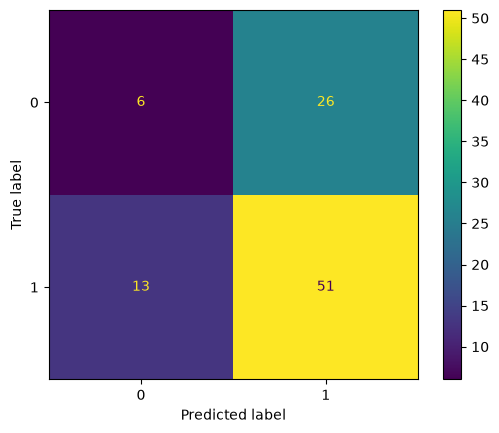

In [32]:
description = "Model trained on new data collected and new model"
with mlflow.start_run(description = description):
    model = KNeighborsClassifier(n_neighbors = 5)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag("mlflow.runName", "knn_run")

    mlflow.log_param("n_neighbors", 5)

    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    cm = ConfusionMatrixDisplay.from_estimator(model, X_val, y_val)
    plt.savefig("confusion_matrix.png")
    mlflow.log_artifact("confusion_matrix.png")

    mlflow.sklearn.log_model(model, "my_model", serialization_format = 'pickle')